# GBDT for Time Series Forecasting — Steam game prices

**Goal.** Forecast tomorrow’s price of 300 Steam games from their price history, and compare a naive forecast, XGBoost and LightGBM under a leakage-free, forward-in-time validation.

**Data.** Wannigamage, D., Barlow, M., Lakshika, E., & Kasmarik, K. (2020). *Steam Games Dataset: Player count history, Price history and data about games*. Mendeley Data, V1. doi:10.17632/ycy3sy3vj2.1 (CC BY 4.0).

**Reference paper.** Maidin, S. S., & Yahya, N. (2025). Price trend prediction and discount optimization for video games in online stores using XGBoost and time-series analysis. *IJRM 2*(4), 333–353.

**Pipeline.** 1 Load → 2 Explore → 3 Features (all known at t − 1) → 4 Time-based folds → 5 Train 4 models → 6 Evaluate → 7 Interpret.

## 0 · Setup

In [1]:
import io, os, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2F6FD0", "#D46A22", "#8A93A3"
SEED = 42
np.random.seed(SEED)
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__)

xgboost 3.4.1 | lightgbm 4.7.0


In [2]:
# ---- Configuration -------------------------------------------------------
# Put these files in the same folder as this notebook:
PRICE_ZIP   = "PriceHistory.zip"            # Mendeley: one CSV per game (Date, Initialprice, Finalprice, Discount)
INFO_CSV    = "applicationInformation.csv"  # Mendeley: appid, type, name, ... (ordered by player count)
PANEL_CSV   = "steam_prices_panel.csv"      # created by section 1 (reused if it already exists)

N_GAMES     = 300   # most-played paid games with a complete history
MAX_GAPS    = 5     # max missing days allowed per game
N_SPLITS    = 5     # TimeSeriesSplit folds (on dates)
N_JOBS      = -1    # CPU cores for XGBoost / LightGBM (-1 = all)

## 1 · Load the data and build the panel

Each game is one CSV inside the ZIP. We read them **directly from the ZIP**, keep the most-played paid games with a complete history, fill the few missing days with the previous day’s value, and sort **by date first** (so any row-based split respects time).

In [3]:
if os.path.exists(PANEL_CSV):
    panel = pd.read_csv(PANEL_CSV, parse_dates=["date"])
    print("Loaded existing", PANEL_CSV)
else:
    parts = []
    with zipfile.ZipFile(PRICE_ZIP) as z:
        for name in z.namelist():
            if name.lower().endswith(".csv"):
                d = pd.read_csv(io.BytesIO(z.read(name)), parse_dates=["Date"])
                d.insert(0, "appid", int(os.path.splitext(os.path.basename(name))[0]))
                parts.append(d)
    raw = pd.concat(parts, ignore_index=True)
    raw.columns = ["appid", "date", "initialprice", "finalprice", "discount"]
    print(f"Raw: {len(raw):,} rows, {raw.appid.nunique():,} games, {raw.date.min().date()} → {raw.date.max().date()}")

    info = pd.read_csv(INFO_CSV, encoding="cp1252")          # the file is not UTF-8
    info["popularity_rank"] = np.arange(1, len(info) + 1)
    calendar = pd.date_range(raw.date.min(), raw.date.max(), freq="D")

    summ = raw.groupby("appid").agg(first=("date", "min"), last=("date", "max"), n=("date", "size"),
                                    sale_share=("discount", lambda s: (s > 0).mean()))
    summ["gaps"] = len(calendar) - summ.n
    summ = summ.join(info.set_index("appid")[["name", "type", "popularity_rank"]])
    ok = summ[(summ["first"] == calendar[0]) & (summ["last"] == calendar[-1]) & (summ.gaps <= MAX_GAPS)
              & (summ.type == "game") & (summ.sale_share > 0)]
    chosen = ok.sort_values("popularity_rank").head(N_GAMES).index
    print(f"Eligible games: {len(ok):,} → keeping the {len(chosen)} most played")

    out = []
    for appid, g in raw[raw.appid.isin(chosen)].groupby("appid"):
        g = g.set_index("date").reindex(calendar)
        g["filled"] = g["finalprice"].isna().astype(int)
        g[["initialprice", "finalprice", "discount"]] = g[["initialprice", "finalprice", "discount"]].ffill().bfill()
        g["appid"] = appid
        out.append(g.rename_axis("date").reset_index())
    panel = (pd.concat(out, ignore_index=True)
               .merge(info[["appid", "name", "popularity_rank"]], on="appid")
               [["appid", "name", "popularity_rank", "date", "initialprice", "finalprice", "discount", "filled"]]
               .sort_values(["date", "appid"]).reset_index(drop=True))
    panel.to_csv(PANEL_CSV, index=False)
    print("Saved", PANEL_CSV)

print(f"Panel: {len(panel):,} rows · {panel.appid.nunique()} games · {panel.date.nunique()} days · filled days: {panel.filled.sum()}")
panel.head()

Raw: 725,268 rows, 1,512 games, 2019-04-07 → 2020-08-12
Eligible games: 1,382 → keeping the 300 most played


Saved steam_prices_panel.csv
Panel: 148,200 rows · 300 games · 494 days · filled days: 508


,appid,name,popularity_rank,date,initialprice,finalprice,discount,filled
0,10,Counter-Strike,29,2019-04-07,9.990,9.990,0.000,0
1,70,Half-Life,428,2019-04-07,9.990,9.990,0.000,0
2,80,Counter-Strike: Condition Zero,320,2019-04-07,9.990,9.990,0.000,0
3,220,Half-Life 2,245,2019-04-07,9.990,9.990,0.000,0
4,240,Counter-Strike: Source,67,2019-04-07,9.990,9.990,0.000,0


## 2 · Explore: how do Steam prices behave?

In [4]:
s = panel.sort_values(["appid", "date"])
changed = s.groupby("appid").finalprice.diff().fillna(0) != 0
on = (s.discount > 0).astype(int)
runs = on.groupby((on != on.shift()).cumsum()).agg(["first", "size"])

stats = pd.DataFrame({
    "Maidin & Yahya (2025)": ["73,000", "$39.52", "75%", "—", "—"],
    "This panel": [f"{len(panel):,}", f"${panel.finalprice.mean():.2f}", f"{(panel.discount == 0).mean():.0%}",
                   f"{changed.mean():.1%}", f"{runs[runs['first'] == 1]['size'].median():.0f} days"]},
    index=["Records", "Mean price", "Days at full price", "Days the price changes", "Typical sale length"])
stats

,Maidin & Yahya (2025),This panel
Records,"73,000","148,200"
Mean price,$39.52,$23.09
Days at full price,75%,83%
Days the price changes,—,3.9%
Typical sale length,—,7 days


In [5]:
# Leakage check: is today's price a formula of today's list price and discount?
err = (panel.finalprice - panel.initialprice * (1 - panel.discount / 100)).abs()
print(f"price = list × (1 − discount) holds within 1 cent in {(err <= 0.01).mean():.2%} of rows")
print("→ using today's discount or list price as a feature would leak the target.")

price = list × (1 − discount) holds within 1 cent in 99.98% of rows
→ using today's discount or list price as a feature would leak the target.


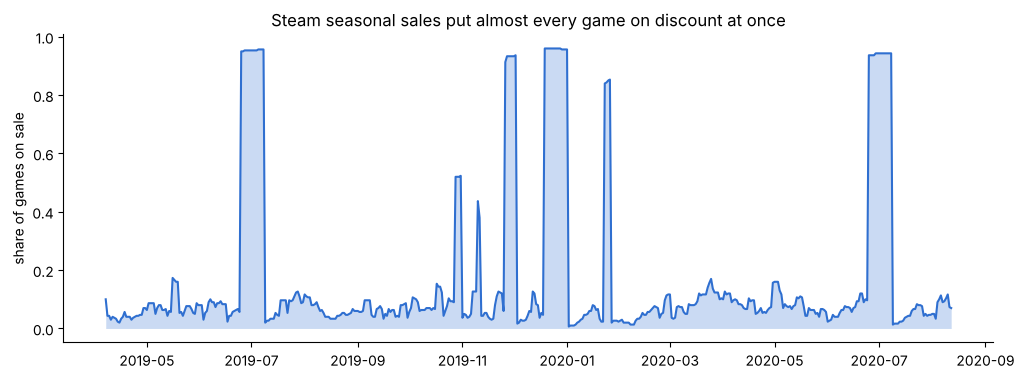

In [6]:
# Store-wide sales: share of games on discount each day
share = panel.groupby("date").discount.apply(lambda x: (x > 0).mean())
fig, ax = plt.subplots()
ax.fill_between(share.index, share.values, color=BLUE, alpha=.25, lw=0)
ax.plot(share.index, share.values, color=BLUE, lw=1.5)
ax.set_ylabel("share of games on sale"); ax.set_title("Steam seasonal sales put almost every game on discount at once")
plt.show()

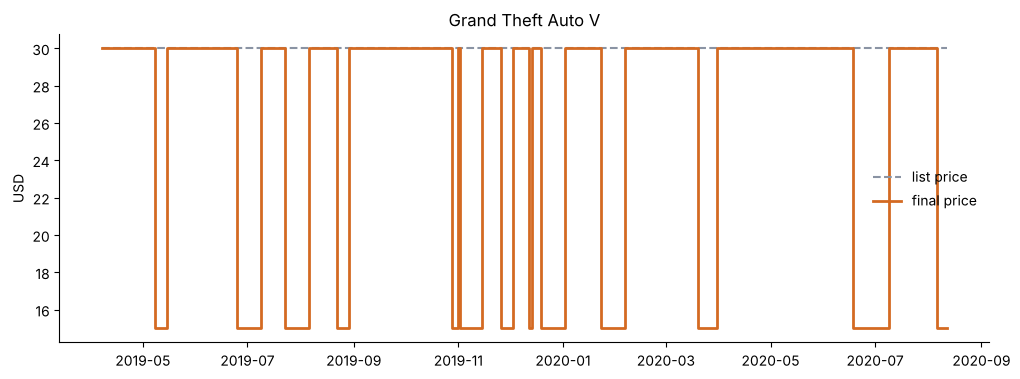

In [7]:
# One game's price history
EXAMPLE_APPID = panel.loc[panel.name.str.contains("Grand Theft Auto V", na=False), "appid"].iloc[0]
ex = panel[panel.appid == EXAMPLE_APPID]
fig, ax = plt.subplots()
ax.step(ex.date, ex.initialprice, where="post", color=GREY, ls="--", label="list price")
ax.step(ex.date, ex.finalprice, where="post", color=ORANGE, lw=2, label="final price")
ax.set_ylabel("USD"); ax.set_title(ex.name.iloc[0]); ax.legend(frameon=False)
plt.show()

## 3 · Feature engineering (everything known at the end of day t − 1)

Target: **final price on day t**. Every price feature is built from days ≤ t − 1 (`shift(1)` before any window), so the model never sees the answer.

The **Steam sale calendar** is exogenous and announced in advance by Valve, so it is a legitimate feature for day t. Dates: Summer 2019 (Jun 25–Jul 9), Halloween (Oct 28–Nov 1), Autumn (Nov 26–Dec 3), Winter (Dec 19–Jan 2), Lunar New Year 2020 (Jan 23–27), Summer 2020 (Jun 25–Jul 9). Sales end at 10 am Pacific on the last day, so that day is counted as not on sale in daily snapshots.

In [8]:
df = panel.sort_values(["appid", "date"]).reset_index(drop=True)
g = df.groupby("appid")
price = g.finalprice

# Lags
for k in [1, 3, 7, 14]:
    df[f"price_lag_{k}"] = price.shift(k)
df["discount_lag_1"]   = g.discount.shift(1)
df["list_price_lag_1"] = g.initialprice.shift(1)

# Rolling statistics on the PAST only (shift first, then roll)
past = price.shift(1)
for w in [7, 30]:
    df[f"price_roll_mean_{w}"] = past.groupby(df.appid).transform(lambda x: x.rolling(w).mean())
    df[f"price_roll_std_{w}"]  = past.groupby(df.appid).transform(lambda x: x.rolling(w).std())

# Momentum and position relative to list price
df["momentum_7"]    = (df.price_lag_1 - df.price_lag_7) / df.price_lag_7
df["ratio_to_list"] = df.price_lag_1 / df.list_price_lag_1

# Days since the price last changed (as of t − 1)
chg = (price.diff() != 0).astype(int)
df["days_since_change"] = (chg.groupby(df.appid).transform(lambda c: c.groupby(c.cumsum()).cumcount())
                              .groupby(df.appid).shift(1))

# Calendar of day t
df["dayofweek"]  = df.date.dt.dayofweek
df["month"]      = df.date.dt.month
df["weekofyear"] = df.date.dt.isocalendar().week.astype(int)
df["dayofyear"]  = df.date.dt.dayofyear

# Steam sale calendar of day t (announced in advance)
SALES = [("2019-06-25", "2019-07-09"), ("2019-10-28", "2019-11-01"), ("2019-11-26", "2019-12-03"),
         ("2019-12-19", "2020-01-02"), ("2020-01-23", "2020-01-27"), ("2020-06-25", "2020-07-09")]
days = pd.date_range("2019-01-01", "2020-12-31")
event = pd.Series(0, index=days); event_day = pd.Series(-1, index=days)
for a, b in SALES:
    r = pd.date_range(a, b, inclusive="left"); event[r] = 1; event_day[r] = np.arange(len(r))
starts = pd.to_datetime([a for a, _ in SALES])
df["steam_sale_event"]   = df.date.map(event)
df["event_day"]          = df.date.map(event_day)
df["days_to_next_event"] = df.date.map(lambda d: min([(s - d).days for s in starts if s >= d] or [365]))

CALENDAR_SALE = ["steam_sale_event", "event_day", "days_to_next_event"]
FEATURES = (["price_lag_1", "price_lag_3", "price_lag_7", "price_lag_14", "discount_lag_1", "list_price_lag_1",
             "price_roll_mean_7", "price_roll_std_7", "price_roll_mean_30", "price_roll_std_30",
             "momentum_7", "ratio_to_list", "days_since_change",
             "dayofweek", "month", "weekofyear", "dayofyear"] + CALENDAR_SALE)
LEAKY = ["discount", "initialprice"]   # TODAY's values: only for the leakage experiment

df = df.dropna(subset=FEATURES).sort_values(["date", "appid"]).reset_index(drop=True)
df["changed"] = df.finalprice != df.price_lag_1
print(f"{len(df):,} rows × {len(FEATURES)} features (first 30 days dropped for the 30-day window)")
df.loc[df.appid == EXAMPLE_APPID, ["date", "finalprice"] + FEATURES[:8]].iloc[205:212]

139,200 rows × 20 features (first 30 days dropped for the 30-day window)


,date,finalprice,price_lag_1,price_lag_3,price_lag_7,price_lag_14,discount_lag_1,list_price_lag_1,price_roll_mean_7,price_roll_std_7
61632,2019-11-28,14.990,14.990,29.990,29.990,14.990,50.000,29.990,25.704,7.319
61932,2019-11-29,14.990,14.990,14.990,29.990,29.990,50.000,29.990,23.561,8.018
62232,2019-11-30,14.990,14.990,14.990,29.990,29.990,50.000,29.990,21.419,8.018
62532,2019-12-01,14.990,14.990,14.990,29.990,29.990,50.000,29.990,19.276,7.319
62832,2019-12-02,14.990,14.990,14.990,29.990,29.990,50.000,29.990,17.133,5.669
63132,2019-12-03,29.990,14.990,14.990,14.990,29.990,50.000,29.990,14.990,0.000
63432,2019-12-04,29.990,29.990,14.990,14.990,29.990,0.000,29.990,17.133,5.669


## 4 · Forward-in-time validation

`TimeSeriesSplit` is applied to the **unique dates**, not to rows: every fold trains on all games up to a date and tests on all games in the next block of days.

Fold 1: train 2019-05-07 → 2019-07-24 (79 days) | test 2019-07-25 → 2019-10-09 (77 days)
Fold 2: train 2019-05-07 → 2019-10-09 (156 days) | test 2019-10-10 → 2019-12-25 (77 days)
Fold 3: train 2019-05-07 → 2019-12-25 (233 days) | test 2019-12-26 → 2020-03-11 (77 days)
Fold 4: train 2019-05-07 → 2020-03-11 (310 days) | test 2020-03-12 → 2020-05-27 (77 days)
Fold 5: train 2019-05-07 → 2020-05-27 (387 days) | test 2020-05-28 → 2020-08-12 (77 days)


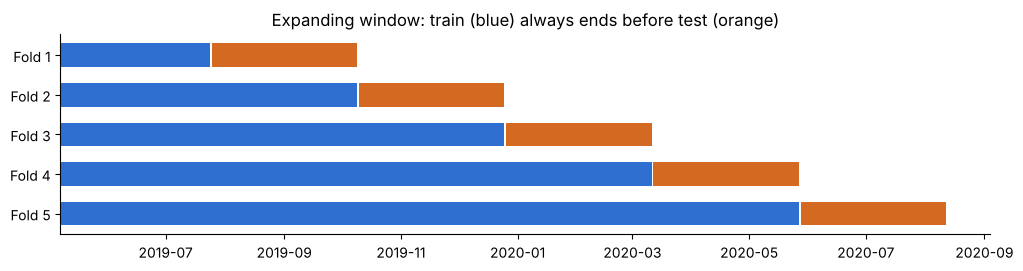

In [9]:
dates = np.sort(df.date.unique())
tss = TimeSeriesSplit(n_splits=N_SPLITS)
folds = []
for i, (tr, te) in enumerate(tss.split(dates), 1):
    folds.append((i, dates[tr], dates[te]))
    print(f"Fold {i}: train {pd.Timestamp(dates[tr][0]).date()} → {pd.Timestamp(dates[tr][-1]).date()} "
          f"({len(tr)} days) | test {pd.Timestamp(dates[te][0]).date()} → {pd.Timestamp(dates[te][-1]).date()} ({len(te)} days)")
    assert dates[tr].max() < dates[te].min()

fig, ax = plt.subplots(figsize=(12, 2.6))
for i, tr, te in folds:
    ax.barh(i, pd.Timestamp(tr[-1]) - pd.Timestamp(tr[0]), left=pd.Timestamp(tr[0]), color=BLUE, height=.6)
    ax.barh(i, pd.Timestamp(te[-1]) - pd.Timestamp(te[0]), left=pd.Timestamp(te[0]), color=ORANGE, height=.6)
ax.invert_yaxis(); ax.set_yticks([f[0] for f in folds], [f"Fold {f[0]}" for f in folds])
ax.set_title("Expanding window: train (blue) always ends before test (orange)")
plt.show()

## 5 · Models

| Model | Target | Loss | Features |
|---|---|---|---|
| **Naive** | — | — | tomorrow = today (`price_lag_1`) |
| **XGBoost (paper setup)** | price level | squared error | all |
| **LightGBM (improved)** | relative change vs yesterday | absolute error (L1) | all |
| **XGBoost + leakage** | price level | squared error | all + **today’s** discount and list price |

Hyperparameters follow the paper: `learning_rate=0.05`, `max_depth=7`, `n_estimators=500`.

In [10]:
P = dict(n_estimators=500, learning_rate=0.05, max_depth=7, random_state=SEED, n_jobs=N_JOBS)

def make_xgb():  return xgb.XGBRegressor(**P, tree_method="hist", objective="reg:squarederror")
def make_lgbm(): return lgb.LGBMRegressor(**P, num_leaves=63, objective="l1", verbose=-1)

MODELS = {
    "Naive":              dict(model=None,      target="level",    features=[]),
    "XGBoost (paper)":    dict(model=make_xgb,  target="level",    features=FEATURES),
    "LightGBM (improved)":dict(model=make_lgbm, target="relative", features=FEATURES),
    "XGBoost + leakage":  dict(model=make_xgb,  target="level",    features=FEATURES + LEAKY),
}

def fit_predict(spec, train, test):
    if spec["model"] is None:
        return test.price_lag_1.values, None
    X_tr, X_te = train[spec["features"]], test[spec["features"]]
    m = spec["model"]()
    if spec["target"] == "relative":           # predict % change, then convert back to a price
        m.fit(X_tr, train.finalprice / train.price_lag_1 - 1)
        return test.price_lag_1.values * (1 + m.predict(X_te)), m
    m.fit(X_tr, train.finalprice)
    return m.predict(X_te), m

def metrics(y, p, changed):
    return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** 0.5, R2=r2_score(y, p),
                MAE_change_days=mean_absolute_error(y[changed], p[changed]))

In [11]:
rows, last_preds, fitted = [], {}, {}
for i, tr_dates, te_dates in folds:
    train, test = df[df.date.isin(tr_dates)], df[df.date.isin(te_dates)]
    for name, spec in MODELS.items():
        t0 = time.time()
        pred, m = fit_predict(spec, train, test)
        rows.append(dict(fold=i, model=name, **metrics(test.finalprice.values, pred, test.changed.values),
                         seconds=time.time() - t0))
        if i == N_SPLITS:
            last_preds[name] = pred; fitted[name] = m
    print(f"Fold {i} done")
results = pd.DataFrame(rows)
test_last = df[df.date.isin(folds[-1][2])].copy()

Fold 1 done


Fold 2 done


Fold 3 done


Fold 4 done


Fold 5 done


## 6 · Results

In [12]:
order = list(MODELS)
summary = (results.groupby("model")[["MAE", "RMSE", "R2", "MAE_change_days", "seconds"]].mean().loc[order])
base = summary.loc["Naive"]
summary["RMSE vs naive"]          = (summary.RMSE / base.RMSE - 1).map("{:+.0%}".format)
summary["change-day MAE vs naive"] = (summary.MAE_change_days / base.MAE_change_days - 1).map("{:+.0%}".format)
summary.to_csv("results_summary.csv")
results.to_csv("results_by_fold.csv", index=False)
summary

,MAE,RMSE,R2,MAE_change_days,seconds,RMSE vs naive,change-day MAE vs naive
model,,,,,,,
Naive,0.685,4.015,0.929,17.295,0.004,+0%,+0%
XGBoost (paper),1.755,3.968,0.933,9.977,2.211,-1%,-42%
LightGBM (improved),0.734,3.495,0.946,12.362,2.157,-13%,-29%
XGBoost + leakage,0.048,0.427,0.999,0.398,1.986,-89%,-98%


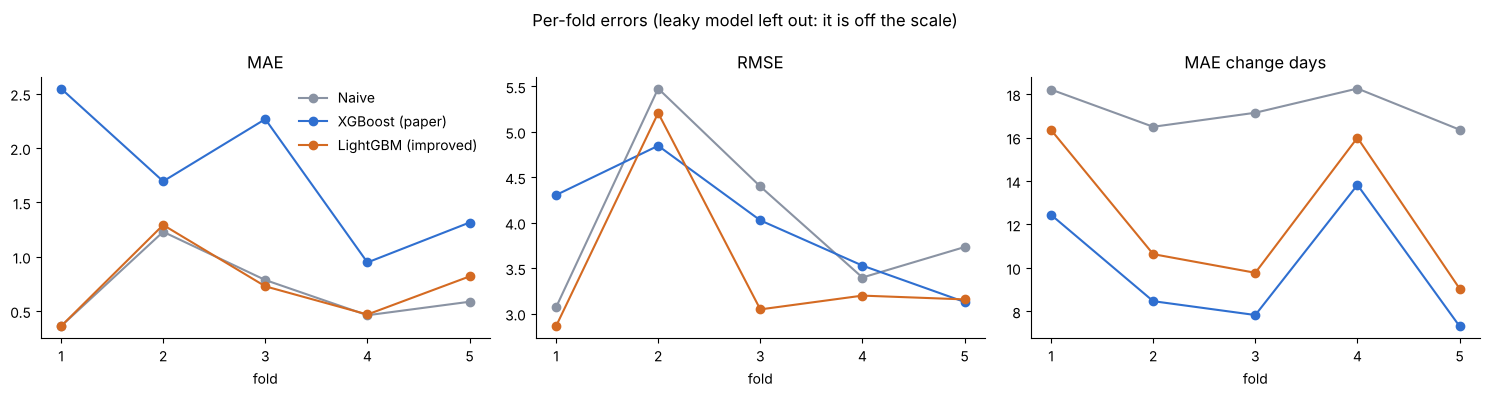

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axs, ["MAE", "RMSE", "MAE_change_days"]):
    pv = results.pivot(index="fold", columns="model", values=col)[order[:3]]
    pv.plot(ax=ax, marker="o", color=[GREY, BLUE, ORANGE], legend=(col == "MAE"))
    ax.set_title(col.replace("_", " ")); ax.set_xticks(range(1, N_SPLITS + 1))
axs[0].legend(frameon=False)
plt.suptitle("Per-fold errors (leaky model left out: it is off the scale)"); plt.tight_layout(); plt.show()

**How to read this.** On the 96% of days when nothing happens, the naive forecast is exactly right, so it is very hard to beat on MAE. Gradient boosting earns its keep on the **days the price changes**, and on RMSE, which punishes the big misses at the start and end of sales. The leaky model looks perfect, which is the warning: an R² near 1 on prices usually means the answer is in the features.

## 7 · Actual vs predicted (last fold, interactive)

In [14]:
GAME = EXAMPLE_APPID   # change to any appid in the panel
mask = (test_last.appid == GAME).values
fig = go.Figure()
fig.add_trace(go.Scatter(x=test_last.date[mask], y=test_last.finalprice[mask], name="actual",
                         line=dict(color="#14213D", width=3, shape="hv")))
for name, color in [("Naive", GREY), ("XGBoost (paper)", BLUE), ("LightGBM (improved)", ORANGE)]:
    fig.add_trace(go.Scatter(x=test_last.date[mask], y=last_preds[name][mask], name=name,
                             line=dict(color=color, width=2, dash="dot" if name == "Naive" else "solid")))
fig.update_layout(title=f"{test_last.name[mask].iloc[0]} — last test fold", yaxis_title="USD",
                  template="simple_white", height=420, legend=dict(orientation="h", y=1.12))
fig.show()

## 8 · Which features drive the forecast?

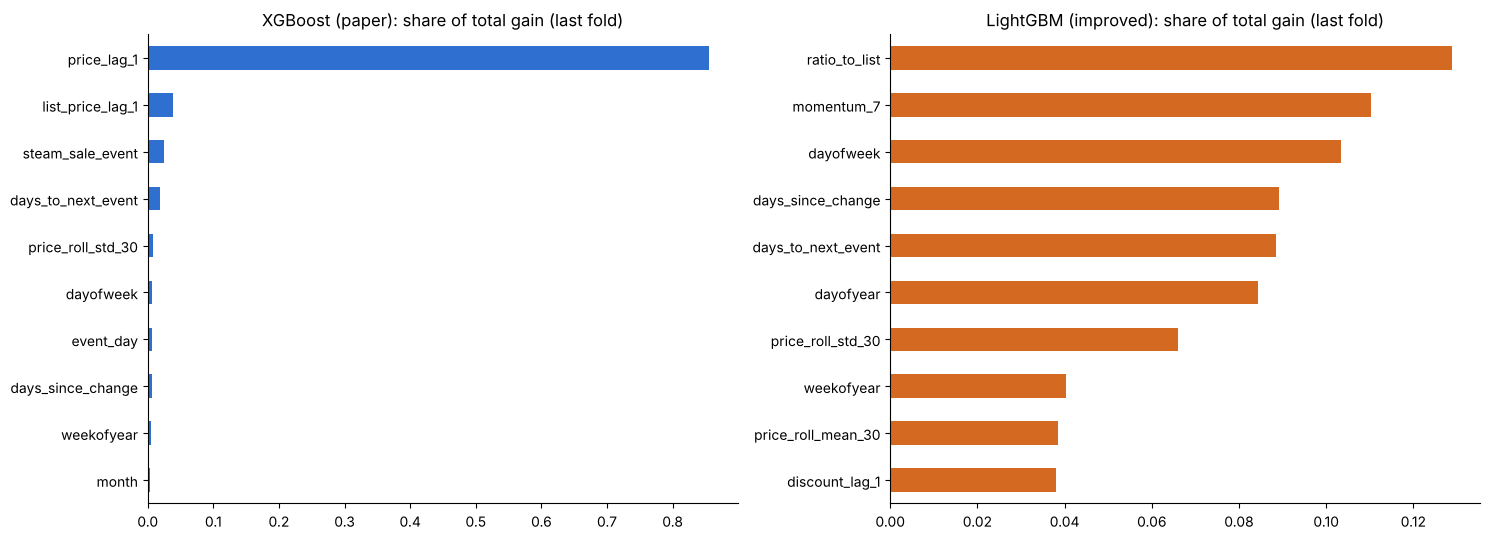

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, name, color in [(axs[0], "XGBoost (paper)", BLUE), (axs[1], "LightGBM (improved)", ORANGE)]:
    m = fitted[name]
    if name.startswith("XGBoost"):
        gain = pd.Series(m.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)
    else:
        gain = pd.Series(m.booster_.feature_importance(importance_type="gain"), index=FEATURES)
    (gain / gain.sum()).sort_values().tail(10).plot.barh(ax=ax, color=color)
    ax.set_title(f"{name}: share of total gain (last fold)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 9 · Ablation: how much does the Steam sale calendar add?

In [16]:
no_cal = dict(model=make_lgbm, target="relative", features=[f for f in FEATURES if f not in CALENDAR_SALE])
abl = []
for i, tr_dates, te_dates in folds:
    train, test = df[df.date.isin(tr_dates)], df[df.date.isin(te_dates)]
    pred, _ = fit_predict(no_cal, train, test)
    abl.append(metrics(test.finalprice.values, pred, test.changed.values))
pd.DataFrame({"LightGBM without sale calendar": pd.DataFrame(abl).mean(),
              "LightGBM (improved)": summary.loc["LightGBM (improved)", ["MAE", "RMSE", "R2", "MAE_change_days"]].astype(float)}).T

,MAE,RMSE,R2,MAE_change_days
LightGBM without sale calendar,0.711,3.734,0.938,14.163
LightGBM (improved),0.734,3.495,0.946,12.362


## 10 · Conclusions

1. **Build every feature from the past only.** Today’s discount or list price turns forecasting into arithmetic (R² ≈ 0.999).
2. **Split on dates, not rows**, and always report a **naive baseline**: with prices that rarely move, it is the bar to clear.
3. **Choose the target and the loss on purpose.** Predicting the relative change with an absolute-error loss matches the naive MAE while cutting RMSE and change-day error.
4. **Known future events matter.** The announced sale calendar is the strongest single improvement on the days when prices change.